# 25 - Boost (MOSFET+Diodo+PWM): Fixed vs Variable

Comparacao do mesmo conversor com **chaveamento explicito** (`MOSFET + diodo + PWM`) em:
- `fixed step`
- `variable step`

Campanha pesada incluida para medir convergencia/custo e evidenciar limites numericos do backend em circuito comutado.

> **Afetado por defeito conhecido (ver KNOWN_LIMITATIONS):** em circuito
> comutado `p.run_transient_adaptive` difere do passo fixo mesmo no mesmo
> `dt` (buck deste notebook: 7.96 V contra 8.04 V; `dt/10` e TR-BDF2 dao
> 8.05 V). Use os numeros do modo `variable` so como comparacao de custo.


In [2]:
import time
import statistics
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import pulsim as p

print("Pulsim:", p.__version__)

Pulsim: 2.0.0


## 1) Parametros de campanha


In [3]:
CONVERTER_ID = "boost_mosfet_pwm"

# Perfil pesado (ajuste se quiser acelerar)
STRESS_HEAVY = True

BASE_TSTOP = 4e-3 if STRESS_HEAVY else 1.5e-3
BASE_DT_FIXED = 2e-6 if STRESS_HEAVY else 3e-6

print("CONVERTER_ID:", CONVERTER_ID)
print("BASE_TSTOP:", BASE_TSTOP)
print("BASE_DT_FIXED:", BASE_DT_FIXED)


CONVERTER_ID: boost_mosfet_pwm
BASE_TSTOP: 0.004
BASE_DT_FIXED: 2e-06


## 2) Construcao do circuito comutado (MOSFET + diodo + PWM)

Os parametros do dispositivo foram amaciados para manter robustez no modo `fixed` durante varreduras longas.


In [4]:
def build_converter(duty: float, fsw: float, r_load: float):
    # v2: ideal gate-mask switch (low-side); PWM moves to switch_fn.
    b = p.CircuitBuilder()
    b.add_voltage_source("Vin", "in", "gnd", 18.0)
    b.add_inductor("L1", "in", "sw", 220e-6)
    b.add_switch("M1", "sw", "gnd", 1.0e3, 1.0e-3)      # low-side
    b.add_diode("D1", "sw", "out", 5.0, 1e-4, 0.7)
    b.add_capacitor("C1", "out", "gnd", 220e-6)
    b.add_resistor("Rload", "out", "gnd", float(r_load))
    b.add_resistor("Rb_sw", "sw", "gnd", 1e5)
    return b, {"n_out_name": "out", "n_sw_name": "sw"}


## 3) Solver setup e funcao de execucao

- `fixed`: `p.simulate(..., dt=)` — motor `pwl` de passo fixo (trapezoidal)
- `variable`: `p.run_transient_adaptive(...)` — driver Python por segmentos
- metricas de cauda: ultimos 20 % do **tempo**, media ponderada no tempo


In [5]:
def run_case(step_mode: str, duty: float, fsw: float, r_load: float, tstop: float, dt_fixed: float):
    b, nodes = build_converter(duty=duty, fsw=fsw, r_load=r_load)
    sw_fn = p.make_pwm_switch_fn(frequency=fsw, duty=duty, switch_idx=0,
                                 num_switches=b.graph.num_switches)

    t0 = time.perf_counter()
    if step_mode == "fixed":
        res = p.simulate(b, t_end=tstop, dt=dt_fixed, switch_fn=sw_fn)
    else:
        res = p.run_transient_adaptive(b, t_end=tstop, dt_init=dt_fixed, switch_fn=sw_fn)
    elapsed = time.perf_counter() - t0

    times = np.asarray(res.times, dtype=float)
    states = np.asarray(res.states, dtype=float)
    out = {
        "mode": step_mode, "success": True, "message": "ok",
        "elapsed_s": float(elapsed), "steps": int(res.num_steps()),
        "rejections": int(getattr(res, "n_rejected", 0)), "newton_total": 0,
        "time": times, "vout": np.array([], dtype=float), "vsw": np.array([], dtype=float),
    }
    if len(times) > 5 and states.shape[0] > 5:
        vout = states[:, b.node_id_of(nodes["n_out_name"])]
        vsw = states[:, b.node_id_of(nodes["n_sw_name"])]
        out["vout"] = vout; out["vsw"] = vsw
        # Last 20 % of the TIME span, time-weighted: on the variable grid the
        # last 20 % of the samples is another window, and a sample mean
        # over-weights the dense regions (AI_GUIDE trap 2).
        t_from = times[0] + 0.8 * (times[-1] - times[0])
        seg = vout[times >= t_from]
        out["vout_final"] = float(vout[-1])
        out["vout_mean_tail"] = float(p.time_average(times, vout, t_from=t_from))
        out["vout_ripple_tail"] = float(np.max(seg) - np.min(seg))
    else:
        out["vout_final"] = out["vout_mean_tail"] = out["vout_ripple_tail"] = float("nan")
    return out


## 4) Caso base (same converter, fixed vs variable)


In [6]:
base_scenario = {"name": "G0", "duty": 0.25, "fsw": 11e3, "r_load": 20.0}

scenarios = [
    {"name": "G1", "duty": 0.15, "fsw": 8e3,  "r_load": 15.0},
    {"name": "G2", "duty": 0.20, "fsw": 10e3, "r_load": 18.0},
    {"name": "G3", "duty": 0.25, "fsw": 11e3, "r_load": 20.0},
    {"name": "G4", "duty": 0.30, "fsw": 12e3, "r_load": 22.0},
    {"name": "G5", "duty": 0.35, "fsw": 15e3, "r_load": 30.0},
    {"name": "G6", "duty": 0.28, "fsw": 14e3, "r_load": 25.0},
]


In [7]:
base_fixed = run_case(
    step_mode="fixed",
    duty=base_scenario["duty"],
    fsw=base_scenario["fsw"],
    r_load=base_scenario["r_load"],
    tstop=BASE_TSTOP,
    dt_fixed=BASE_DT_FIXED,
)

base_variable = run_case(
    step_mode="variable",
    duty=base_scenario["duty"],
    fsw=base_scenario["fsw"],
    r_load=base_scenario["r_load"],
    tstop=BASE_TSTOP,
    dt_fixed=BASE_DT_FIXED,
)

for item in (base_fixed, base_variable):
    print("-" * 72)
    print("mode:", item["mode"])
    print("success:", item["success"])
    print("message:", item["message"])
    print("elapsed_s:", f"{item['elapsed_s']:.4f}")
    print("steps:", item["steps"], "rejections:", item["rejections"], "newton_total:", item["newton_total"])
    if item["success"]:
        print("vout_final:", f"{item['vout_final']:.4f} V")
        print("vout_mean_tail:", f"{item['vout_mean_tail']:.4f} V")
        print("vout_ripple_tail:", f"{item['vout_ripple_tail']*1e3:.3f} mV")


------------------------------------------------------------------------
mode: fixed
success: True
message: ok
elapsed_s: 0.0013
steps: 2001 rejections: 0 newton_total: 0
vout_final: 23.6899 V
vout_mean_tail: 24.8246 V
vout_ripple_tail: 2338.772 mV
------------------------------------------------------------------------
mode: variable
success: True
message: ok
elapsed_s: 0.0034
steps: 2001 rejections: 20 newton_total: 0
vout_final: 23.7178 V
vout_mean_tail: 24.8530 V
vout_ripple_tail: 2354.505 mV


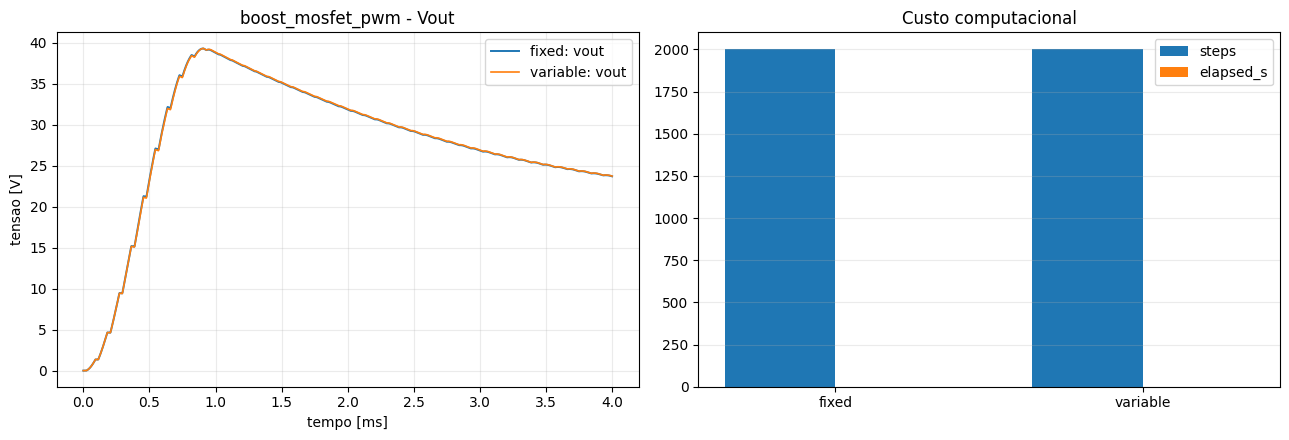

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

if base_fixed["success"]:
    ax[0].plot(base_fixed["time"] * 1e3, base_fixed["vout"], lw=1.4, label="fixed: vout")
if base_variable["success"]:
    ax[0].plot(base_variable["time"] * 1e3, base_variable["vout"], lw=1.2, label="variable: vout")

ax[0].set_title(f"{CONVERTER_ID} - Vout")
ax[0].set_xlabel("tempo [ms]")
ax[0].set_ylabel("tensao [V]")
ax[0].grid(True, alpha=0.25)
ax[0].legend()

labels = ["fixed", "variable"]
steps = [base_fixed["steps"], base_variable["steps"]]
elapsed = [base_fixed["elapsed_s"], base_variable["elapsed_s"]]

x = np.arange(len(labels))
bw = 0.36
ax[1].bar(x - bw/2, steps, width=bw, label="steps")
ax[1].bar(x + bw/2, elapsed, width=bw, label="elapsed_s")
ax[1].set_xticks(x)
ax[1].set_xticklabels(labels)
ax[1].set_title("Custo computacional")
ax[1].grid(True, axis="y", alpha=0.25)
ax[1].legend()

plt.tight_layout()
plt.show()


## 5) Campanha pesada de estresse


In [9]:
campaign_results = []
for sc in scenarios:
    for mode in ("fixed", "variable"):
        result = run_case(
            step_mode=mode,
            duty=sc["duty"],
            fsw=sc["fsw"],
            r_load=sc["r_load"],
            tstop=BASE_TSTOP,
            dt_fixed=BASE_DT_FIXED,
        )
        result["scenario"] = sc["name"]
        result["duty"] = sc["duty"]
        result["fsw"] = sc["fsw"]
        result["r_load"] = sc["r_load"]
        campaign_results.append(result)

print("Casos executados:", len(campaign_results))


Casos executados: 12


In [10]:
def summarize_mode(results, mode):
    data = [r for r in results if r["mode"] == mode]
    ok = [r for r in data if r["success"]]
    fail = [r for r in data if not r["success"]]

    success_rate = (len(ok) / max(1, len(data))) * 100.0
    med_elapsed = statistics.median([r["elapsed_s"] for r in data]) if data else float("nan")
    med_steps = statistics.median([r["steps"] for r in data]) if data else float("nan")
    med_rej = statistics.median([r["rejections"] for r in data]) if data else float("nan")

    fail_msgs = Counter(r["message"] for r in fail)
    top_fail = fail_msgs.most_common(3)

    return {
        "mode": mode,
        "n": len(data),
        "n_ok": len(ok),
        "n_fail": len(fail),
        "success_rate": success_rate,
        "median_elapsed_s": med_elapsed,
        "median_steps": med_steps,
        "median_rejections": med_rej,
        "top_fail": top_fail,
    }


sum_fixed = summarize_mode(campaign_results, "fixed")
sum_variable = summarize_mode(campaign_results, "variable")

for s in (sum_fixed, sum_variable):
    print("=" * 76)
    print("mode:", s["mode"])
    print("casos:", s["n"], "ok:", s["n_ok"], "fail:", s["n_fail"], "success_rate:", f"{s['success_rate']:.1f}%")
    print("median_elapsed_s:", f"{s['median_elapsed_s']:.4f}")
    print("median_steps:", int(s["median_steps"]))
    print("median_rejections:", int(s["median_rejections"]))
    if s["n_fail"] > 0:
        print("top_fail_messages:")
        for msg, cnt in s["top_fail"]:
            print(f"  - {cnt}x {msg}")

if sum_fixed["n_ok"] > 0 and sum_variable["n_ok"] > 0:
    speedup = sum_fixed["median_elapsed_s"] / max(1e-12, sum_variable["median_elapsed_s"])
    step_reduction = sum_fixed["median_steps"] / max(1e-12, sum_variable["median_steps"])
    print("=" * 76)
    print(f"speedup mediano (fixed/variable): {speedup:.2f}x")
    print(f"reducao mediana de passos (fixed/variable): {step_reduction:.2f}x")
else:
    print("=" * 76)
    print("Comparacao direta de speedup nao disponivel (um dos modos nao convergiu em nenhum caso).")


mode: fixed
casos: 6 ok: 6 fail: 0 success_rate: 100.0%
median_elapsed_s: 0.0009
median_steps: 2001
median_rejections: 0
mode: variable
casos: 6 ok: 6 fail: 0 success_rate: 100.0%
median_elapsed_s: 0.0038
median_steps: 2001
median_rejections: 20
speedup mediano (fixed/variable): 0.23x
reducao mediana de passos (fixed/variable): 1.00x


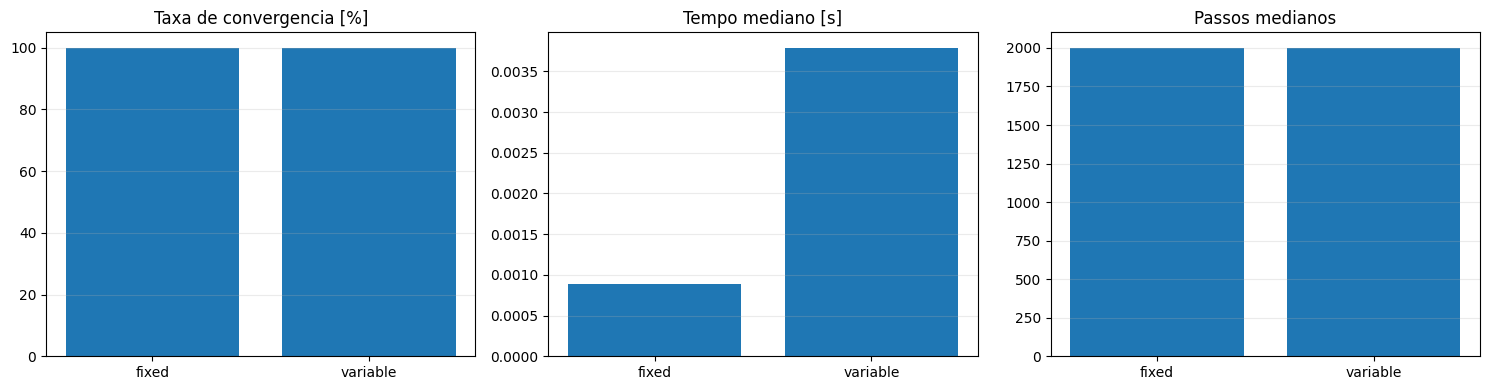

In [11]:
labels = ["fixed", "variable"]
summary = [sum_fixed, sum_variable]

success_rate = [s["success_rate"] for s in summary]
med_elapsed = [s["median_elapsed_s"] for s in summary]
med_steps = [s["median_steps"] for s in summary]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].bar(labels, success_rate)
ax[0].set_ylim([0, 105])
ax[0].set_title("Taxa de convergencia [%]")
ax[0].grid(True, axis="y", alpha=0.25)

ax[1].bar(labels, med_elapsed)
ax[1].set_title("Tempo mediano [s]")
ax[1].grid(True, axis="y", alpha=0.25)

ax[2].bar(labels, med_steps)
ax[2].set_title("Passos medianos")
ax[2].grid(True, axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
